# Appliances Energy Regression — All-in-One Notebook

**This is a standalone notebook:** the cleaned dataset is embedded inside this `.ipynb` file. You do not need to download or keep separate Excel files to run it.

## Included
- Embedded cleaned dataset
- Data types, null values, unique values, duplicate checks
- Summary statistics and target distribution plot
- Potential outlier check (outliers are retained)
- Date-based feature creation
- Existing Train/Test split
- Linear Regression model
- MAE, RMSE and R² evaluation
- Actual-vs-predicted graph and prediction preview
- Optional export of report and predictions to Excel when the notebook runs

In [1]:
import warnings
warnings.filterwarnings("ignore")

import base64
import gzip
import io
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Load the dataset embedded in this notebook
The complete cleaned dataset is stored in the next cell, so no external dataset file is required.

In [2]:
# Embedded compressed CSV dataset — included inside this notebook file.
_EMBEDDED_DATA_GZIP_BASE64 = """..."""

_csv_bytes = gzip.decompress(base64.b64decode(_EMBEDDED_DATA_GZIP_BASE64))
df = pd.read_csv(io.BytesIO(_csv_bytes))
if "date" in df.columns:
    df["date"] = pd.to_datetime(df["date"], errors="coerce")

TARGET = "Appliances_Wh"
if TARGET not in df.columns:
    raise ValueError(f"Required target column '{TARGET}' is missing.")

print("Dataset loaded from inside this notebook.")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded from inside this notebook.
Dataset shape: (19735, 29)


,date,Split,Appliances_Wh,Lights_Wh,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1
0,2016-01-11 17:00:00,Train,60,30,19.89,47.597,19.2,44.790,19.79,44.730,19.000,45.567,17.167,55.20,7.027,84.257,17.200,41.627,18.2,48.900,17.033,45.53,6.600,733.5,92.0,7.000,63.000,5.3,13.275
1,2016-01-11 17:10:00,Train,60,30,19.89,46.693,19.2,44.722,19.79,44.790,19.000,45.992,17.167,55.20,6.833,84.063,17.200,41.560,18.2,48.863,17.067,45.56,6.483,733.6,92.0,6.667,59.167,5.2,18.606
2,2016-01-11 17:20:00,Train,50,30,19.89,46.300,19.2,44.627,19.79,44.933,18.927,45.890,17.167,55.09,6.560,83.157,17.200,41.433,18.2,48.730,17.000,45.50,6.367,733.7,92.0,6.333,55.333,5.1,28.643
3,2016-01-11 17:30:00,Train,50,40,19.89,46.067,19.2,44.590,19.79,45.000,18.890,45.723,17.167,55.09,6.433,83.423,17.133,41.290,18.1,48.590,17.000,45.40,6.250,733.8,92.0,6.000,51.500,5.0,45.410
4,2016-01-11 17:40:00,Train,60,40,19.89,46.333,19.2,44.530,19.79,45.000,18.890,45.530,17.200,55.09,6.367,84.893,17.200,41.230,18.1,48.590,17.000,45.40,6.133,733.9,92.0,5.667,47.667,4.9,10.084


In [3]:
# Safe cleaning and data-quality checks
before_rows = len(df)
df = df.drop_duplicates().copy()
df = df.loc[df[TARGET].notna()].copy()
if 'date' in df.columns:
    df = df.loc[df['date'].notna()].copy()
if 'rv1' in df.columns and 'rv2' in df.columns and df['rv1'].equals(df['rv2']):
    df = df.drop(columns=['rv2'])
df = df.reset_index(drop=True)
print('Rows before cleaning:', before_rows)
print('Rows after cleaning:', len(df))
print('Columns after cleaning:', len(df.columns))

Rows before cleaning: 19735
Rows after cleaning: 19735
Columns after cleaning: 29


## 2. Data types, null values, unique values, and duplicates

In [4]:
overview = pd.DataFrame({
    "Data_Type": df.dtypes.astype(str),
    "Missing_Values": df.isna().sum(),
    "Unique_Values": df.nunique(dropna=False)
})
display(overview)
print("Total missing cells:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))

,Data_Type,Missing_Values,Unique_Values
date,datetime64[ns],0,19735
Split,object,0,2
Appliances_Wh,int64,0,92
Lights_Wh,int64,0,8
T1,float64,0,707
RH_1,float64,0,2522
T2,float64,0,1616
RH_2,float64,0,3304
T3,float64,0,1399
RH_3,float64,0,2550


Total missing cells: 0
Exact duplicate rows: 0


## 3. Summary statistics and target distribution

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,19735,NaN,NaN,NaN,2016-03-20 05:30:00,2016-01-11 17:00:00,2016-02-14 23:15:00,2016-03-20 05:30:00,2016-04-23 11:45:00,2016-05-27 18:00:00,NaN
Split,19735,2,Train,14801,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Appliances_Wh,19735.0,NaN,NaN,NaN,97.694958,10.0,50.0,60.0,100.0,1080.0,102.524891
Lights_Wh,19735.0,NaN,NaN,NaN,3.801875,0.0,0.0,0.0,0.0,70.0,7.935988
T1,19735.0,NaN,NaN,NaN,21.686572,16.79,20.76,21.6,22.6,26.26,1.606066
RH_1,19735.0,NaN,NaN,NaN,40.259739,27.023,37.333,39.657,43.067,63.36,3.979296
T2,19735.0,NaN,NaN,NaN,20.341219,16.1,18.79,20.0,21.5,29.857,2.192976
RH_2,19735.0,NaN,NaN,NaN,40.420422,20.463,37.9,40.5,43.26,56.027,4.069814
T3,19735.0,NaN,NaN,NaN,22.26761,17.2,20.79,22.1,23.29,29.236,2.00611
RH_3,19735.0,NaN,NaN,NaN,39.242499,28.767,36.9,38.53,41.76,50.163,3.254577


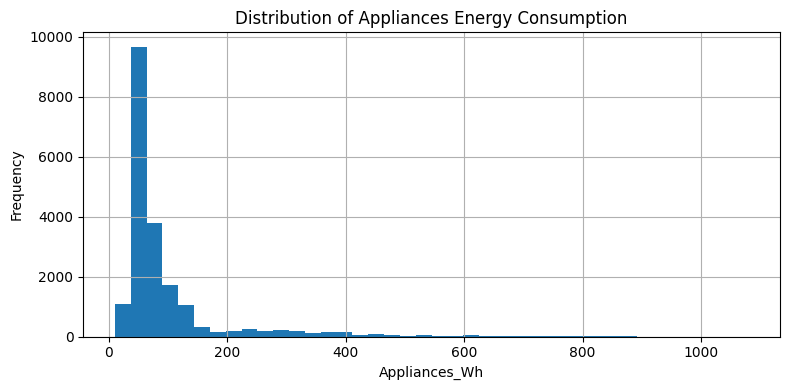

In [5]:
display(df.describe(include="all").T)

plt.figure(figsize=(8, 4))
df[TARGET].hist(bins=40)
plt.title("Distribution of Appliances Energy Consumption")
plt.xlabel("Appliances_Wh")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## 4. Potential outliers (flag only; do not automatically delete)

In [6]:
q1 = df[TARGET].quantile(0.25)
q3 = df[TARGET].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outlier_mask = (df[TARGET] < lower_bound) | (df[TARGET] > upper_bound)

print(f"IQR lower bound: {lower_bound:.2f}")
print(f"IQR upper bound: {upper_bound:.2f}")
print(f"Potential target outliers: {int(outlier_mask.sum())} ({outlier_mask.mean():.2%})")
print("Potential outliers are retained; investigate before removing any.")

IQR lower bound: -25.00
IQR upper bound: 175.00
Potential target outliers: 2138 (10.83%)
Potential outliers are retained; investigate before removing any.


## 5. Create time-based features

In [7]:
if "date" in df.columns:
    df["hour"] = df["date"].dt.hour
    df["day_of_week"] = df["date"].dt.dayofweek
    df["month"] = df["date"].dt.month
    df["is_weekend"] = (df["date"].dt.dayofweek >= 5).astype(int)
    df["time_index_hours"] = (
        (df["date"] - df["date"].min()).dt.total_seconds() / 3600.0
    )
display(df[["date", "hour", "day_of_week", "month", "is_weekend", "time_index_hours"]].head())

,date,hour,day_of_week,month,is_weekend,time_index_hours
0,2016-01-11 17:00:00,17,0,1,0,0.000000
1,2016-01-11 17:10:00,17,0,1,0,0.166667
2,2016-01-11 17:20:00,17,0,1,0,0.333333
3,2016-01-11 17:30:00,17,0,1,0,0.500000
4,2016-01-11 17:40:00,17,0,1,0,0.666667


## 6. Use the existing Train/Test split

In [8]:
if "Split" in df.columns:
    split_labels = df["Split"].astype(str).str.strip().str.lower()
    train_mask = split_labels.eq("train")
    test_mask = split_labels.eq("test")
    if train_mask.sum() == 0 or test_mask.sum() == 0:
        raise ValueError("Split column must contain Train and Test labels.")
    train_df = df.loc[train_mask].copy()
    test_df = df.loc[test_mask].copy()
    print("Using the predefined Train/Test split.")
else:
    df = df.sort_values("date").reset_index(drop=True) if "date" in df.columns else df.reset_index(drop=True)
    cut = int(len(df) * 0.8)
    train_df, test_df = df.iloc[:cut].copy(), df.iloc[cut:].copy()
    print("Split column not found; used chronological 80/20 split.")

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

Using the predefined Train/Test split.
Training rows: 14801
Testing rows: 4934


## 7. Prepare features and train Linear Regression

In [9]:
excluded = [TARGET, "Split", "date"]
feature_cols = [c for c in df.columns if c not in excluded]

X_train = train_df[feature_cols].select_dtypes(include=[np.number]).copy()
X_test = test_df[feature_cols].select_dtypes(include=[np.number]).copy()
X_test = X_test.reindex(columns=X_train.columns)
y_train = train_df[TARGET].astype(float)
y_test = test_df[TARGET].astype(float)

if X_train.shape[1] == 0:
    raise ValueError("No numeric feature columns were found.")

model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", LinearRegression())
])
model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Model trained successfully.")
print("Number of features:", X_train.shape[1])

Model trained successfully.
Number of features: 31


## 8. Evaluate the model

In [10]:
mae = mean_absolute_error(y_test, predictions)
rmse = float(np.sqrt(mean_squared_error(y_test, predictions)))
r2 = r2_score(y_test, predictions)

metrics = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score"],
    "Value": [mae, rmse, r2]
})
display(metrics)
print(f"MAE: {mae:.3f} Wh")
print(f"RMSE: {rmse:.3f} Wh")
print(f"R² Score: {r2:.4f}")

,Metric,Value
0,MAE,49.718606
1,RMSE,84.330256
2,R2 Score,0.087538


MAE: 49.719 Wh
RMSE: 84.330 Wh
R² Score: 0.0875


## 9. Actual vs predicted

,Actual_Appliances_Wh,Predicted_Appliances_Wh,Absolute_Error_Wh
0,280.0,164.113695,115.886305
1,320.0,182.767835,137.232165
2,360.0,195.085323,164.914677
3,210.0,206.727918,3.272082
4,90.0,226.248135,136.248135
5,100.0,220.813187,120.813187
6,90.0,217.622826,127.622826
7,90.0,208.280262,118.280262
8,100.0,198.431300,98.431300
9,100.0,191.543339,91.543339


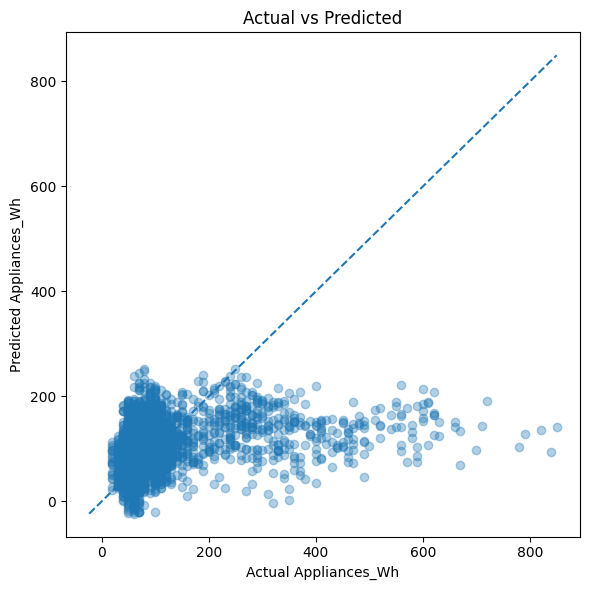

In [11]:
results = pd.DataFrame({
    "Actual_Appliances_Wh": y_test.to_numpy(),
    "Predicted_Appliances_Wh": predictions
})
results["Absolute_Error_Wh"] = (
    results["Actual_Appliances_Wh"] - results["Predicted_Appliances_Wh"]
).abs()
display(results.head(15))

plt.figure(figsize=(6, 6))
plt.scatter(results["Actual_Appliances_Wh"], results["Predicted_Appliances_Wh"], alpha=0.35)
lims = [
    min(results["Actual_Appliances_Wh"].min(), results["Predicted_Appliances_Wh"].min()),
    max(results["Actual_Appliances_Wh"].max(), results["Predicted_Appliances_Wh"].max())
]
plt.plot(lims, lims, linestyle="--")
plt.xlabel("Actual Appliances_Wh")
plt.ylabel("Predicted Appliances_Wh")
plt.title("Actual vs Predicted")
plt.tight_layout()
plt.show()

## 10. Export optional Excel outputs
This cell creates report and prediction Excel files in the notebook folder. The notebook itself does not depend on these files.

In [12]:
quality_report = pd.DataFrame({
    "Check": [
        "Rows used", "Columns after cleaning",
        "Missing cells", "Duplicate rows",
        "Training rows", "Testing rows",
        "Potential IQR target outliers retained"
    ],
    "Result": [
        len(df), len(df.columns), int(df.isna().sum().sum()),
        int(df.duplicated().sum()), len(train_df), len(test_df), int(outlier_mask.sum())
    ]
})

try:
    with pd.ExcelWriter("Appliances_Energy_Regression_Report.xlsx", engine="openpyxl") as writer:
        quality_report.to_excel(writer, sheet_name="Quality_Report", index=False)
        metrics.to_excel(writer, sheet_name="Model_Metrics", index=False)
    results.to_excel("Appliances_Energy_Regression_Predictions.xlsx", index=False)
    print("Optional Excel report and prediction files saved successfully.")
except Exception as exc:
    print("Excel export could not be completed in this environment:", exc)
    print("The model results above are still available in the notebook.")

Optional Excel report and prediction files saved successfully.


## Conclusion
This notebook is self-contained: the dataset is embedded inside the `.ipynb` file. Keep this one file and open it in Jupyter Notebook or JupyterLab. Run **Run → Run All Cells** from top to bottom.

If you see an import error, install the required packages in your active Python environment:
`pip install pandas numpy matplotlib scikit-learn openpyxl`